--- FINAL RESULTS ---
True Hidden Probabilities : [0.1  0.5  0.85 0.3  0.7 ]
Final Reward Sums per Arm : [  0.   0. 836.   0.  22.]
Pull Counts per Arm : [  1.   1. 970.   1.  27.]
Final Estimated Rewards : [0.    0.    0.862 0.    0.815]
Total Cumulative Reward : 858


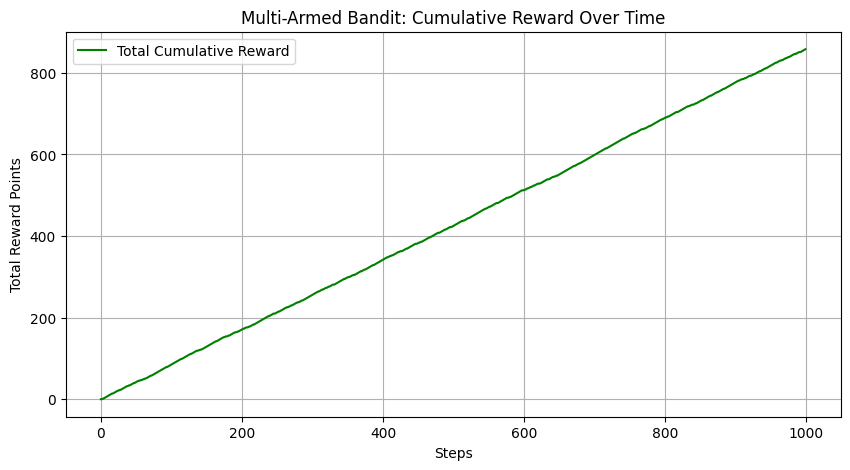

In [1]:
import numpy as np
import matplotlib.pyplot as plt
n_arms = 5
true_probs = np.array([0.10, 0.50, 0.85, 0.30, 0.70])
n_steps = 1000
reward_sums = np.zeros(n_arms)
counts = np.zeros(n_arms)
estimated_rewards = np.zeros(n_arms)
reward_history = []
cumulative_rewards = []
total_running_reward = 0
for arm in range(n_arms):
    reward = 1 if np.random.rand() < true_probs[arm] else 0
    counts[arm] += 1
    reward_sums[arm] += reward
    estimated_rewards[arm] = reward_sums[arm] / counts[arm]
    reward_history.append(reward)
    total_running_reward += reward
    cumulative_rewards.append(total_running_reward)
for step in range(n_arms, n_steps):
    action = np.argmax(estimated_rewards)
    reward = 1 if np.random.rand() < true_probs[action] else 0
    counts[action] += 1
    reward_sums[action] += reward
    estimated_rewards[action] = reward_sums[action] / counts[action]
    reward_history.append(reward)
    total_running_reward += reward
    cumulative_rewards.append(total_running_reward)
print("--- FINAL RESULTS ---")
print(f"True Hidden Probabilities : {true_probs}")
print(f"Final Reward Sums per Arm : {reward_sums}")
print(f"Pull Counts per Arm : {counts}")
print(f"Final Estimated Rewards : {np.round(estimated_rewards, 3)}")
print(f"Total Cumulative Reward : {total_running_reward}")
plt.figure(figsize=(10, 5))
plt.plot(cumulative_rewards, label='Total Cumulative Reward', color='green')
plt.title('Multi-Armed Bandit: Cumulative Reward Over Time')
plt.xlabel('Steps')
plt.ylabel('Total Reward Points')
plt.legend()
plt.grid(True)
plt.show()